# Практическая задача 2. Реализация внимания в RNN

Источник: `materials/notes/disciplines__nlp__laboratory-works__attention.md`. Основа — пайплайн ЛР 2 (`solution/lab2/lab2.ipynb`), датасет `Petitions.csv`.

## 1. База из ЛР 2: данные, предобработка, словарь, DataLoader

Архитектура без внимания: Embedding → RNN/LSTM/GRU → Linear (Many-to-One по `h_n`). Ниже — тот же пайплайн; затем добавим attention-слой.

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

DEVICE = torch.device('cpu')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA_PATH = Path('../../materials/dataset/Petitions.csv')
SAMPLE_SIZE = 6000
VOCAB_SIZE = 8000
MAX_SEQ_LEN = 60
EMBED_DIM = 64
HIDDEN_DIM = 128
BATCH_SIZE = 64
EPOCHS = 6
LR = 1e-3

TEXT_COL = 'public_petition_text'
TARGET_COL = 'reason_category'

df = pd.read_csv(DATA_PATH)
df = df[[TEXT_COL, TARGET_COL]].dropna().copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)
df[TARGET_COL] = df[TARGET_COL].astype(str)
df, _ = train_test_split(
    df,
    train_size=min(SAMPLE_SIZE, len(df)),
    stratify=df[TARGET_COL],
    random_state=SEED,
)
df = df.reset_index(drop=True)
print('Корпус:', len(df), 'категорий:', df[TARGET_COL].nunique())


def tokenize(text: str) -> list[str]:
    text = text.lower()
    text = re.sub(r'[^а-яёa-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split()


df['tokens'] = df[TEXT_COL].map(tokenize)

le = LabelEncoder()
df['y'] = le.fit_transform(df[TARGET_COL])
num_classes = len(le.classes_)

train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df['y'], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

counter = Counter()
for toks in train_df['tokens']:
    counter.update(toks)
itos = ['<pad>', '<unk>'] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}


def encode(tokens: list[str]) -> list[int]:
    ids = [stoi.get(t, 1) for t in tokens][:MAX_SEQ_LEN]
    return ids


class TextDataset(Dataset):
    def __init__(self, frame: pd.DataFrame):
        self.seqs = [encode(t) for t in frame['tokens']]
        self.y = frame['y'].to_numpy()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.seqs[idx], self.y[idx]


def collate(batch):
    seqs, ys = zip(*batch)
    lengths = torch.tensor([max(len(s), 1) for s in seqs], dtype=torch.long)
    max_len = int(lengths.max())
    x = torch.zeros(len(seqs), max_len, dtype=torch.long)
    for i, s in enumerate(seqs):
        if s:
            x[i, : len(s)] = torch.tensor(s, dtype=torch.long)
        else:
            x[i, 0] = 1  # <unk>, длина уже 1
            lengths[i] = 1
    return x, lengths, torch.tensor(ys, dtype=torch.long)


train_loader = DataLoader(TextDataset(train_df), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
test_loader = DataLoader(TextDataset(test_df), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

y_train = train_df['y'].to_numpy()
class_counts = np.bincount(y_train, minlength=num_classes).astype(np.float32)
class_weights = torch.tensor(class_counts.sum() / np.maximum(class_counts, 1.0), dtype=torch.float32)
class_weights = class_weights / class_weights.mean()
majority_acc = float((test_df['y'] == np.bincount(y_train).argmax()).mean())
print('vocab:', len(itos), 'majority test acc:', round(majority_acc, 4))


Корпус: 6000 категорий: 15


vocab: 8000 majority test acc: 0.58


## 2. Attention-слой (dot-product)

По методичке: на вход все скрытые состояния `out` и финальное `h_n`, оценки $e_i = \langle h_i, h_n \rangle$, $\alpha = \mathrm{softmax}(e)$, контекст $\sum_i \alpha_i h_i$, выход $c = [h_n \,|\, \sum_i \alpha_i h_i]$.

В формуле методички в знаменателе softmax написано $\sum e_j$; по определению softmax используем $\sum \exp(e_j)$ (как в лекции nmt-2 / transformer). Padding-позиции маскируем до softmax.

In [2]:
class DotProductAttention(nn.Module):
    """c = [h_n | sum alpha_i h_i], e_i = <h_i, h_n> — ПЗ attention.md."""

    def forward(self, out: torch.Tensor, h_n: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # out: (B, T, H), h_n: (B, H)
        # e_i = h_i^T h_n
        scores = torch.bmm(out, h_n.unsqueeze(2)).squeeze(2)  # (B, T)
        max_len = out.size(1)
        mask = torch.arange(max_len, device=out.device).unsqueeze(0) >= lengths.unsqueeze(1)
        scores = scores.masked_fill(mask, float('-inf'))
        alpha = F.softmax(scores, dim=1)  # (B, T)
        context = torch.bmm(alpha.unsqueeze(1), out).squeeze(1)  # (B, H)
        return torch.cat([h_n, context], dim=1)  # (B, 2H)


class BaselineClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, rnn_type='rnn'):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        rnn_cls = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[rnn_type]
        self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
        self.rnn_type = rnn_type

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        h_n = hidden[0] if self.rnn_type == 'lstm' else hidden
        return self.fc(h_n[-1])


class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, rnn_type='rnn'):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        rnn_cls = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[rnn_type]
        self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True)
        self.attention = DotProductAttention()
        self.fc = nn.Linear(2 * hidden_dim, num_classes)  # вход — вектор c
        self.rnn_type = rnn_type

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, hidden = self.rnn(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True)
        h_n = hidden[0] if self.rnn_type == 'lstm' else hidden
        h_last = h_n[-1]
        c = self.attention(out, h_last, lengths.to(out.device))
        return self.fc(c)


print(DotProductAttention())


DotProductAttention()


## 3. Интеграция внимания в RNN, LSTM и GRU

Обучаем три baseline-модели (как в ЛР 2) и три с attention-слоем.

In [3]:
def train_model(model, loader, criterion, optimizer, epochs=EPOCHS):
    model.train()
    history = []
    for epoch in range(1, epochs + 1):
        total, n = 0.0, 0
        for xb, lengths, yb in loader:
            xb, lengths, yb = xb.to(DEVICE), lengths.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb, lengths), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
            n += len(yb)
        history.append(total / n)
        print(f'  epoch {epoch}/{epochs} loss={history[-1]:.4f}')
    return history


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    preds, trues = [], []
    for xb, lengths, yb in loader:
        logits = model(xb.to(DEVICE), lengths.to(DEVICE))
        preds.extend(logits.argmax(dim=1).cpu().numpy().tolist())
        trues.extend(yb.numpy().tolist())
    return {
        'accuracy': accuracy_score(trues, preds),
        'precision': precision_score(trues, preds, average='macro', zero_division=0),
        'recall': recall_score(trues, preds, average='macro', zero_division=0),
        'f1': f1_score(trues, preds, average='macro', zero_division=0),
    }


vocab_n = len(itos)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
results = {}
loss_hist = {}

for rnn_type in ('rnn', 'lstm', 'gru'):
    for use_attn in (False, True):
        key = f'{rnn_type.upper()}+attn' if use_attn else rnn_type.upper()
        print('===', key, '===')
        torch.manual_seed(SEED)
        cls = AttentionClassifier if use_attn else BaselineClassifier
        model = cls(vocab_n, EMBED_DIM, HIDDEN_DIM, num_classes, rnn_type=rnn_type).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        loss_hist[key] = train_model(model, train_loader, criterion, opt)
        results[key] = evaluate_model(model, test_loader)
        print({k: round(v, 4) for k, v in results[key].items()})


=== RNN ===


  epoch 1/6 loss=2.6078


  epoch 2/6 loss=2.1386


  epoch 3/6 loss=1.7406


  epoch 4/6 loss=1.3964


  epoch 5/6 loss=1.0555


... (32 outputs left out)

  epoch 4/6 loss=1.1487


  epoch 5/6 loss=0.8251


  epoch 6/6 loss=0.5684


{'accuracy': 0.5325, 'precision': 0.3124, 'recall': 0.5058, 'f1': 0.3459}


## 4. Сравнение метрик с / без внимания

Критерий приёмки: сравнение метрик attention vs исходные архитектуры ЛР 2.

           accuracy  precision  recall      f1
model                                         
RNN          0.4683     0.2436  0.3881  0.2535
RNN+attn     0.3917     0.2168  0.4136  0.2273
LSTM         0.5342     0.2865  0.4932  0.3107
LSTM+attn    0.5342     0.2991  0.5399  0.3334
GRU          0.5692     0.2994  0.5242  0.3326
GRU+attn     0.5325     0.3124  0.5058  0.3459
majority accuracy: 0.58


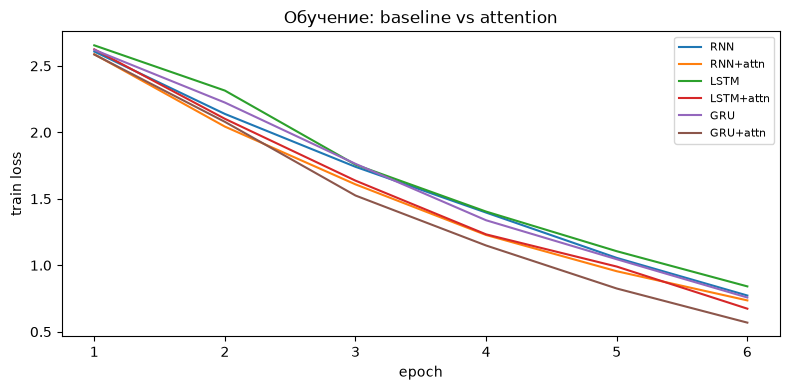


Дельта macro-F1 (attn − baseline):
  RNN: -0.0262
  LSTM: +0.0227
  GRU: +0.0133


In [4]:
rows = []
for key, m in results.items():
    rows.append({'model': key, **{k: round(v, 4) for k, v in m.items()}})
cmp = pd.DataFrame(rows).set_index('model')
print(cmp)
print('majority accuracy:', round(majority_acc, 4))

fig, ax = plt.subplots(figsize=(8, 4))
for key, hist in loss_hist.items():
    ax.plot(range(1, len(hist) + 1), hist, label=key)
ax.set_xlabel('epoch')
ax.set_ylabel('train loss')
ax.legend(fontsize=8)
ax.set_title('Обучение: baseline vs attention')
plt.tight_layout()
plt.show()

print('\nДельта macro-F1 (attn − baseline):')
for base in ('RNN', 'LSTM', 'GRU'):
    d = results[f'{base}+attn']['f1'] - results[base]['f1']
    print(f'  {base}: {d:+.4f}')
